In [9]:
from pathlib import Path
print(list(Path('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train').iterdir()))

[PosixPath('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train/Glioma'), PosixPath('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train/Meningioma'), PosixPath('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train/No Tumor'), PosixPath('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train/Pituitary')]


In [10]:
from pathlib import Path

data_path = Path('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train')
classes = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

missing_labels_paths = []

for cls in classes:
    images_dir_path = data_path / cls / 'images'
    labels_dir_path = data_path / cls / 'labels'
    
    # Parcourir toutes les images du dossier images
    for image_path in images_dir_path.iterdir():
        # Construire le chemin attendu pour le fichier texte
        expected_label_path = labels_dir_path / f"{image_path.stem}.txt"
        
        # Si le fichier .txt n'existe pas, on sauvegarde le chemin de l'image
        if not expected_label_path.exists():
            missing_labels_paths.append(image_path)

# Affichage du résultat final
if not missing_labels_paths:
    print("Vérification réussie : Chaque image possède bien son fichier .txt correspondant.")
else:
    print(f"Problème trouvé : {len(missing_labels_paths)} images n'ont pas de fichier .txt.")

Vérification réussie : Chaque image possède bien son fichier .txt correspondant.


In [11]:
import random
from pathlib import Path
data_path = Path('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train')
classes = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
selected_images_path = []

for cls in classes:
    path = data_path/cls/'images'
    classe_images = list(path.iterdir())
    selected_classe_images = random.sample(classe_images, 2)
    selected_images_path.extend(selected_classe_images)

for img in selected_images_path:
    print(img.name)
    print('')

Tr-gl_0410.jpg

Te-gl_0143.jpg

Tr-me_0975.jpg

Tr-me_0879.jpg

Tr-no_0755.jpg

Tr-no_0523.jpg

Tr-pi_0286.jpg

p (803).jpg



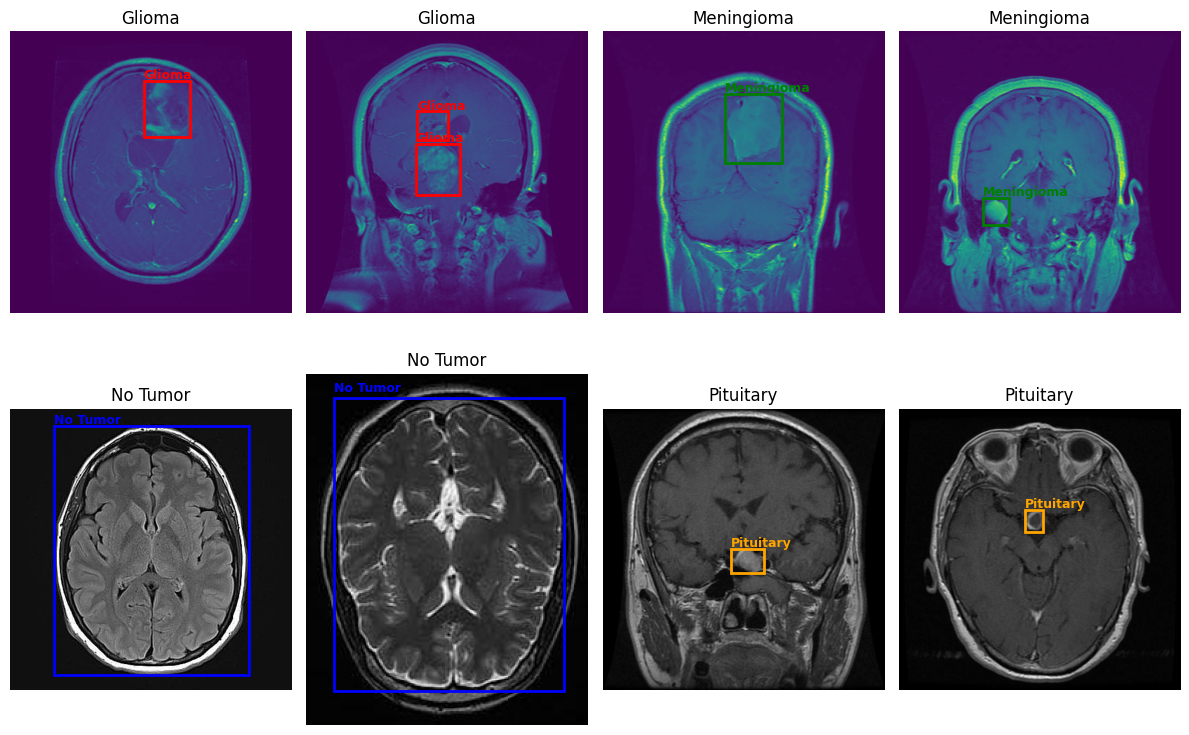

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

plt.figure(figsize=(12, 8))
colors = ['red', 'green', 'blue', 'orange']
classes = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
for i, img_path in enumerate(selected_images_path):
    img = Image.open(img_path)
    img_width, img_height = img.size
    
    label_path = img_path.parent.parent / 'labels' / f"{img_path.stem}.txt"

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(img)
    ax.set_title(img_path.parent.parent.name)
    ax.axis('off')

    if label_path.exists():
        with open(label_path, 'r') as file:
            lines = file.readlines()
            
        for line in lines:
            parts = line.strip().split()
            t_cls, cx, cy, bw, bh = map(float, parts[:])
            
            rect_width = bw * img_width
            rect_height = bh * img_height
            x_min = (cx * img_width) - (rect_width / 2)
            y_min = (cy * img_height) - (rect_height / 2)
            
            rect = patches.Rectangle((x_min, y_min), rect_width, rect_height, 
                                     linewidth=2, edgecolor=colors[int(t_cls)], facecolor='none')
            ax.add_patch(rect)
            ax.text(x_min, y_min - 5, classes[int(t_cls)], color=colors[int(t_cls)], fontsize=9, weight='bold')
                                     

plt.tight_layout()
plt.show()

In [13]:
import random
import shutil
from pathlib import Path

random.seed(42)
src = Path('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Val')
val_path = Path('/kaggle/working/split/val')
test_path = Path('/kaggle/working/split/test')

classes = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

for cls in classes:
    images_dir_path = src / cls / 'images'
    labels_dir_path = src / cls / 'labels'
    
    val_images_dir_path = val_path / cls / 'images'
    val_labels_dir_path = val_path / cls / 'labels'
    
    test_images_dir_path = test_path / cls / 'images'
    test_labels_dir_path = test_path / cls / 'labels'
    
    for dir_path in [val_images_dir_path, val_labels_dir_path, test_images_dir_path, test_labels_dir_path]:
        dir_path.mkdir(parents=True, exist_ok=True)
        
    all_images_paths = list(images_dir_path.iterdir())
    random.shuffle(all_images_paths)
    
    split_index = len(all_images_paths) // 2
    val_images_paths = all_images_paths[:split_index]
    test_images_paths = all_images_paths[split_index:]
    
    def copy_data(images_paths_list, target_images_path, target_labels_path):
        for img_path in images_paths_list:
            shutil.copy(img_path, target_images_path / img_path.name)
            
            lbl_path = labels_dir_path / f"{img_path.stem}.txt"
            if lbl_path.exists():
                shutil.copy(lbl_path, target_labels_path / lbl_path.name)
                
    copy_data(val_images_paths, val_images_dir_path, val_labels_dir_path)
    copy_data(test_images_paths, test_images_dir_path, test_labels_dir_path)

print("Data successfully split: 50% Validation, 50% Test.")

Data successfully split: 50% Validation, 50% Test.


In [14]:
from pathlib import Path

def print_tree(directory, padding=""):
    path = Path(directory)
    print(padding + "├── " + path.name)
    padding += "│   "
    for item in sorted(path.iterdir()):
        if item.is_dir():
            print_tree(item, padding)

print_tree('/kaggle/working/split')

├── split
│   ├── test
│   │   ├── Glioma
│   │   │   ├── images
│   │   │   ├── labels
│   │   ├── Meningioma
│   │   │   ├── images
│   │   │   ├── labels
│   │   ├── No Tumor
│   │   │   ├── images
│   │   │   ├── labels
│   │   ├── Pituitary
│   │   │   ├── images
│   │   │   ├── labels
│   ├── val
│   │   ├── Glioma
│   │   │   ├── images
│   │   │   ├── labels
│   │   ├── Meningioma
│   │   │   ├── images
│   │   │   ├── labels
│   │   ├── No Tumor
│   │   │   ├── images
│   │   │   ├── labels
│   │   ├── Pituitary
│   │   │   ├── images
│   │   │   ├── labels


In [15]:
from pathlib import Path

base_paths = [Path('/kaggle/working/split/val'), Path('/kaggle/working/split/test')]
classes = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

deleted_count = 0

for base_path in base_paths:
    for cls in classes:
        images_dir_path = base_path / cls / 'images'
        labels_dir_path = base_path / cls / 'labels'
        
        image_files = {p.stem: p for p in images_dir_path.iterdir()}
        label_files = {p.stem: p for p in labels_dir_path.iterdir()}
        
        # 1. Delete images without a corresponding .txt label
        for stem, img_path in image_files.items():
            if stem not in label_files:
                img_path.unlink()  # Physically deletes from the folder
                deleted_count += 1
                
        # 2. Delete .txt labels without a corresponding image
        for stem, lbl_path in label_files.items():
            if stem not in image_files:
                lbl_path.unlink()  # Physically deletes from the folder
                deleted_count += 1

print(f"Cleanup complete: {deleted_count} orphaned files permanently deleted from the folders.")

Cleanup complete: 2 orphaned files permanently deleted from the folders.


In [16]:
from pathlib import Path

train_path = Path('/kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train')
val_path = Path('/kaggle/working/split/val')
test_path = Path('/kaggle/working/split/test')

datasets_paths = {'Train': train_path, 'Val': val_path, 'Test': test_path}
classes = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

for dataset_name, base_path in datasets_paths.items():
    print(f"\n{'='*30}\nEnsemble : {dataset_name}\n{'='*30}")
    
    if not base_path.exists():
        print(f"Chemin introuvable : {base_path}")
        continue

    total_images = 0
    total_labels = 0
    format_errors = 0

    for cls in classes:
        images_dir_path = base_path / cls / 'images'
        labels_dir_path = base_path / cls / 'labels'
        
        num_images = len(list(images_dir_path.iterdir())) if images_dir_path.exists() else 0
        num_labels = len(list(labels_dir_path.iterdir())) if labels_dir_path.exists() else 0
        
        total_images += num_images
        total_labels += num_labels
        
        print(f"{cls:<12} -> Images: {num_images:<5} | Labels: {num_labels:<5}")

        if labels_dir_path.exists():
            for label_path in labels_dir_path.iterdir():
                with open(label_path, 'r') as file:
                    for line_num, line in enumerate(file):
                        parts = line.strip().split()
                        
                        if len(parts) != 5:
                            print(f"  [Erreur] Format incorrect (colonnes) : {label_path.name} (Ligne {line_num+1})")
                            format_errors += 1
                            continue
                        
                        try:
                            c_id = int(parts[0])
                            cx, cy, bw, bh = map(float, parts[1:])
                            
                            if c_id not in [0, 1, 2, 3]:
                                print(f"  [Erreur] Classe invalide ({c_id}) : {label_path.name}")
                                format_errors += 1
                            
                            if not (0.0 <= cx <= 1.0 and 0.0 <= cy <= 1.0 and 0.0 <= bw <= 1.0 and 0.0 <= bh <= 1.0):
                                print(f"  [Erreur] Coordonnées hors limites : {label_path.name}")
                                format_errors += 1
                                
                        except ValueError:
                            print(f"  [Erreur] Valeur non numérique : {label_path.name}")
                            format_errors += 1

    print("-" * 30)
    print(f"Total {dataset_name} -> Images: {total_images} | Labels: {total_labels}")
    if format_errors == 0:
        print("Validation YOLO -> OK (0 erreur).")
    else:
        print(f"Validation YOLO -> {format_errors} erreurs trouvées.")


Ensemble : Train
Glioma       -> Images: 1153  | Labels: 1153 
Meningioma   -> Images: 1449  | Labels: 1449 
No Tumor     -> Images: 711   | Labels: 711  
Pituitary    -> Images: 1424  | Labels: 1424 
------------------------------
Total Train -> Images: 4737 | Labels: 4737
Validation YOLO -> OK (0 erreur).

Ensemble : Val
Glioma       -> Images: 68    | Labels: 68   
Meningioma   -> Images: 70    | Labels: 70   
No Tumor     -> Images: 49    | Labels: 49   
Pituitary    -> Images: 68    | Labels: 68   
------------------------------
Total Val -> Images: 255 | Labels: 255
Validation YOLO -> OK (0 erreur).

Ensemble : Test
Glioma       -> Images: 68    | Labels: 68   
Meningioma   -> Images: 70    | Labels: 70   
No Tumor     -> Images: 49    | Labels: 49   
Pituitary    -> Images: 68    | Labels: 68   
------------------------------
Total Test -> Images: 255 | Labels: 255
Validation YOLO -> OK (0 erreur).


In [17]:
yaml_content = """train: /kaggle/input/datasets/rihabsabri/diagnostic-multimodal-ds/Train
val: /kaggle/working/split/val
test: /kaggle/working/split/test

nc: 4
names:
  - Glioma
  - Meningioma
  - No Tumor
  - Pituitary
"""

with open('/kaggle/working/data.yaml', 'w', encoding='utf-8') as f:
    f.write(yaml_content)

print("Fichier data.yaml créé avec succès dans /kaggle/working/")

Fichier data.yaml créé avec succès dans /kaggle/working/


In [19]:
!pip install ultralytics

In [18]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

result = model.train(
    data = '/kaggle/working/data.yaml',
    epochs = 50,
    imgsz = 640,
    batch=16,
    patience=10,
    device=0, # to force GPU i guess
    seed = 42,
    project="/kaggle/working/models/detection",
    name='yolov8n_v1',

    degrees=15.0,
    translate=0.1,
    scale=0.2,
    fliplr=0.5,      
    flipud=0.0,       
    mosaic=1.0,    
    hsv_h=0.015,
    hsv_s=0.7,       
    hsv_v=0.4
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_v1-4, nbs=64, nms=None, opset=None, optimize=False, op

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.63G      1.279      1.318      1.456          2        640: 100% ━━━━━━━━━━━━ 297/297 7.5it/s 39.4s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.9it/s 1.6s0.2s
                   all        255        277      0.707      0.642      0.703      0.354

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.63G      1.269      1.183       1.44          1        640: 100% ━━━━━━━━━━━━ 297/297 7.6it/s 39.3s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 5.3it/s 1.5s0.2s
                   all        255        277      0.857       0.73      0.832      0.468

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.63G      1.236      1.074      1.414          3        640: 100% ━━━━━━━━━━━━ 297/297 7.5it/s 39.5s0.3ss
                 Class     Images 

In [22]:
# Evaluate the best weights on the test split
best_model = YOLO('/kaggle/working/models/detection/yolov8n_v1-4/weights/best.pt')
test_results = best_model.val(data='/kaggle/working/data.yaml', split='test')

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 421.8±143.0 MB/s, size: 13.5 KB)
val: Scanning /kaggle/working/split/test/Glioma/labels... 255 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 255/255 1.2Kit/s 0.2s<0.0s
val: New cache created: /kaggle/working/split/test/Glioma/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 5.9it/s 2.7s0.1s
                   all        255        277      0.951      0.957      0.967       0.78
                Glioma         67         77       0.91      0.919      0.921      0.771
            Meningioma         70         71      0.994      0.986      0.995      0.824
              No Tumor         49         49          1      0.998      0.995      0.766
             Pituitary         77         80      0.89

In [21]:
import os
print(os.listdir('/kaggle/working/models/detection/'))

['yolov8n_v1-3', 'yolov8n_v1-4', 'yolov8n_v1', 'yolov8n_v1-2']


In [24]:
import shutil
import os
from IPython.display import FileLink

# 1. Delete the failed zip file to free up your Kaggle disk space
failed_zip = '/kaggle/working/yolo_project_export.zip'
if os.path.exists(failed_zip):
    os.remove(failed_zip)

# 2. Compress ONLY the models folder (contains weights, metrics, and graphs)
shutil.make_archive('/kaggle/working/yolo_model_results', 'zip', '/kaggle/working/models')

# 3. Generate a clickable link to download
FileLink(r'yolo_model_results.zip')

/kaggle/working/yolo_model_results.zip